In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import shutil
from io import BytesIO
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras.optimizers import Adam
print("done")

done


In [2]:
from PIL import ImageFile

# Allow loading of truncated images in PIL.
# This can be useful when dealing with incomplete image files.

ImageFile.LOAD_TRUNCATED_IMAGES = True

In [3]:
# Build a lightweight file index; image pixels are loaded batch-by-batch by the generators.
data_path = r"E:\SIC_AI\final_project\archive (2)\RGB ArSL dataset"
categories = sorted(
    name for name in os.listdir(data_path)
    if os.path.isdir(os.path.join(data_path, name))
)

file_paths = []
labels = []
valid_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".gif")
for category in categories:
    category_path = os.path.join(data_path, category)
    for img_name in os.listdir(category_path):
        if img_name.lower().endswith(valid_extensions):
            file_paths.append(os.path.join(category_path, img_name))
            labels.append(category)

dataframe = pd.DataFrame({"filename": file_paths, "label": labels})
label_encoder = LabelEncoder()
label_encoder.fit(categories)

# Keep the original 80/10/10 stratified split, storing only paths and labels.
train_df, holdout_df = train_test_split(
    dataframe, test_size=0.2, random_state=42, stratify=dataframe["label"]
)
val_df, test_df = train_test_split(
    holdout_df, test_size=0.5, random_state=42, stratify=holdout_df["label"]
)

# Load images in batches. Only rescale pixel values; apply no random transforms.
train_datagen = ImageDataGenerator(rescale=1.0 / 255.0)
eval_datagen = ImageDataGenerator(rescale=1.0 / 255.0)

common_generator_args = dict(
    x_col="filename",
    y_col="label",
    target_size=(224, 224),
    batch_size=32,
    classes=categories,
    class_mode="categorical",
    validate_filenames=True,
)
train_generator = train_datagen.flow_from_dataframe(
    train_df, shuffle=True, **common_generator_args
)
val_generator = eval_datagen.flow_from_dataframe(
    val_df, shuffle=False, **common_generator_args
)
test_generator = eval_datagen.flow_from_dataframe(
    test_df, shuffle=False, batch_size=128, **{
        key: value for key, value in common_generator_args.items() if key != "batch_size"
    }
)

# Preserve familiar names for downstream notebook cells that use encoded labels.
encoded_labels = label_encoder.transform(dataframe["label"])
categorical_labels = None  # Labels are one-hot encoded per batch by class_mode="categorical".

Found 6284 validated image filenames belonging to 31 classes.
Found 786 validated image filenames belonging to 31 classes.
Found 786 validated image filenames belonging to 31 classes.


In [4]:
# Dataset and generator information (no full image arrays are kept in RAM).
print(f"Total indexed images: {len(dataframe)}")
print(f"Number of categories (classes): {len(categories)}")
print(f"Class names: {label_encoder.classes_}")
print(f"Train / validation / test: {len(train_df)} / {len(val_df)} / {len(test_df)}")
print(f"Class indices: {train_generator.class_indices}")

sample_batch, sample_labels = next(train_generator)
print(f"Batch image shape: {sample_batch.shape}")
print(f"Pixel range after rescaling/augmentation: {sample_batch.min():.2f} to {sample_batch.max():.2f}")
print(f"Batch label shape (one-hot): {sample_labels.shape}")
print(f"Example class: {categories[int(np.argmax(sample_labels[0]))]}")
train_generator.reset()

Total indexed images: 7856
Number of categories (classes): 31
Class names: ['Ain' 'Al' 'Alef' 'Beh' 'Dad' 'Dal' 'Feh' 'Ghain' 'Hah' 'Heh' 'Jeem'
 'Kaf' 'Khah' 'Laa' 'Lam' 'Meem' 'Noon' 'Qaf' 'Reh' 'Sad' 'Seen' 'Sheen'
 'Tah' 'Teh' 'Teh_Marbuta' 'Thal' 'Theh' 'Waw' 'Yeh' 'Zah' 'Zain']
Train / validation / test: 6284 / 786 / 786
Class indices: {'Ain': 0, 'Al': 1, 'Alef': 2, 'Beh': 3, 'Dad': 4, 'Dal': 5, 'Feh': 6, 'Ghain': 7, 'Hah': 8, 'Heh': 9, 'Jeem': 10, 'Kaf': 11, 'Khah': 12, 'Laa': 13, 'Lam': 14, 'Meem': 15, 'Noon': 16, 'Qaf': 17, 'Reh': 18, 'Sad': 19, 'Seen': 20, 'Sheen': 21, 'Tah': 22, 'Teh': 23, 'Teh_Marbuta': 24, 'Thal': 25, 'Theh': 26, 'Waw': 27, 'Yeh': 28, 'Zah': 29, 'Zain': 30}
Batch image shape: (32, 224, 224, 3)
Pixel range after rescaling/augmentation: 0.00 to 1.00
Batch label shape (one-hot): (32, 31)
Example class: Hah


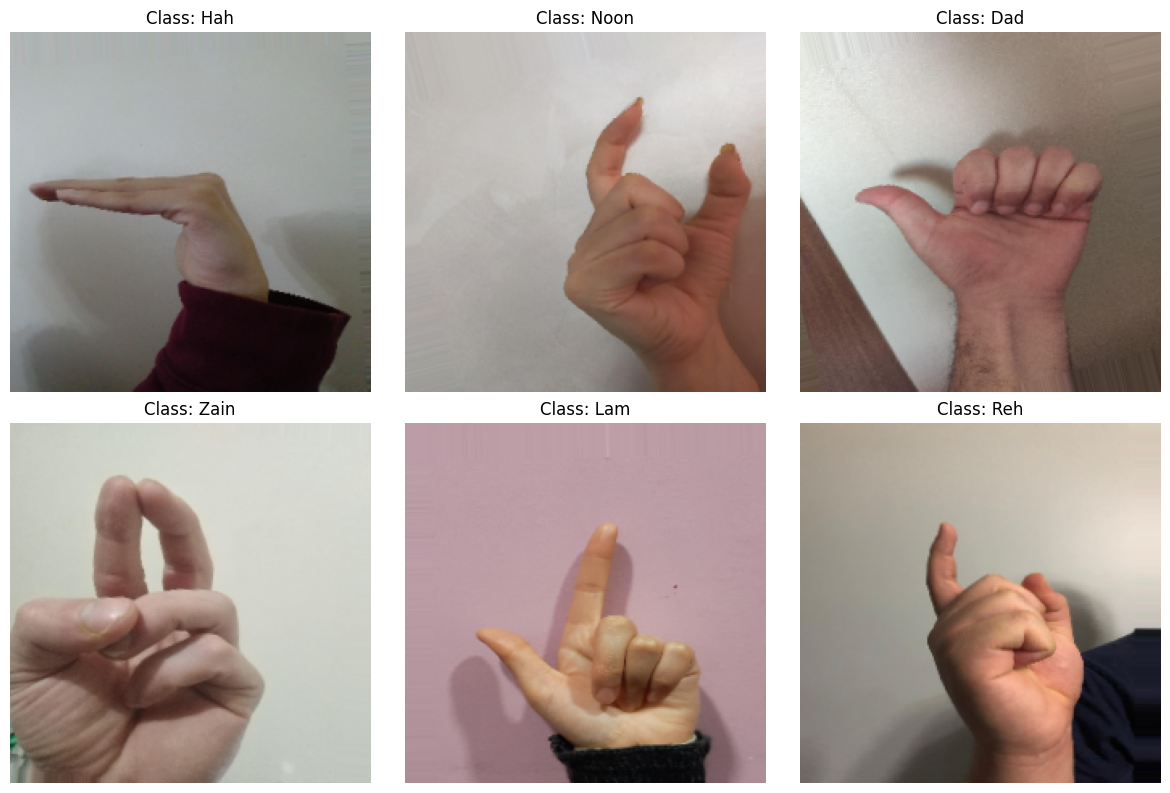

In [5]:
import random

# Display 6 images from one training batch
sample_batch, sample_labels = next(train_generator)
plt.figure(figsize=(12, 8))
for i in range(min(6, len(sample_batch))):
    plt.subplot(2, 3, i + 1)
    plt.imshow(sample_batch[i])
    class_id = int(np.argmax(sample_labels[i]))
    plt.title(f"Class: {categories[class_id]}")
    plt.axis("off")
plt.tight_layout()
plt.show()
train_generator.reset()

C:\Users\osama Aboud\AppData\Local\Temp\ipykernel_11908\4045071287.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=dataframe["label"], order=label_encoder.classes_, palette="viridis")


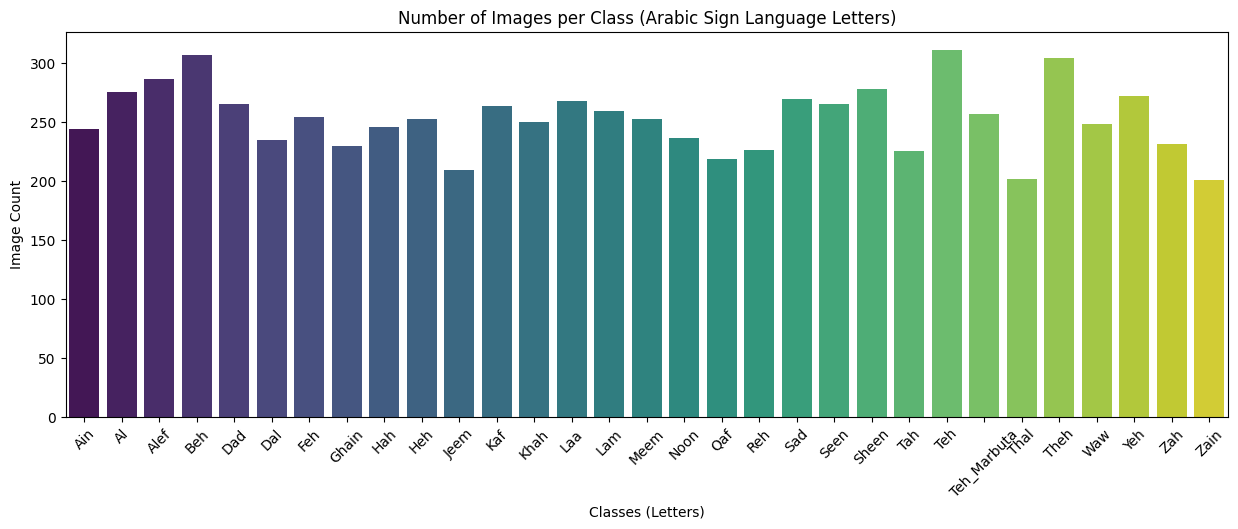

In [6]:
# Check data balance 
plt.figure(figsize=(15, 5))
sns.countplot(x=dataframe["label"], order=label_encoder.classes_, palette="viridis")
plt.title("Number of Images per Class (Arabic Sign Language Letters)")
plt.xlabel("Classes (Letters)")
plt.ylabel("Image Count")
plt.xticks(rotation=45)
plt.show()

In [7]:
print(f"Training samples: {train_generator.samples}")
print(f"Validation samples: {val_generator.samples}")
print(f"Test samples: {test_generator.samples}")
print(f"Steps per training epoch: {len(train_generator)}")
print(f"Validation steps: {len(val_generator)}")
print(f"Test steps: {len(test_generator)}")

Training samples: 6284
Validation samples: 786
Test samples: 786
Steps per training epoch: 197
Validation steps: 25
Test steps: 7
